# Predicting Monthly Salaries from Professional Profiles

This project uses the Koodiklinikka 2025 salary survey to compare
models for predicting gross monthly salary from professional profiles.

Research question:
How accurately can monthly salaries be predicted from professional
profiles, and which modeling approach performs best?

The processed salary variable includes base salary and monthly commission.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("koodiklinikka_2025.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (682, 56)


,Timestamp,Palkansaaja vai laskuttaja,Siirtynyt palkansaaja/laskuttaja,Ikä,Sukupuoli,Suomen kielen taito,Työkieli,Työkokemus alalta (vuosina),Vuosia nykyisellä työnantajalla,Työpaikkojen lukumäärä,...,Data & ML,DevOps & pilvi,Tietokannat,Vapaa sana,Palaute,Vastaustunniste,Vuositulot,Rooli (normalisoitu),Kk-tulot (laskennallinen),"Kk-tulot (laskennallinen, normalisoitu)"
0,2026-02-09 08:08:48.457,Laskuttaja,Ei,36-40,mies,Yes,Both,10.0,4.0,4.0,...,"SQL, Kafka, scikit-learn","CI/CD (GitHub Actions, GitLab CI, Jenkins), AWS","PostgreSQL, Tiger Data (Timescale)",NaN,NaN,2a27944c9ee50d0c,NaN,NaN,NaN,NaN
1,2026-02-09 08:10:51.389,Palkansaaja,Ei,46-50,mies,Yes,Both,20.0,4.0,5.0,...,NaN,"CI/CD (GitHub Actions, GitLab CI, Jenkins), Go...","PostgreSQL, Firestore",NaN,NaN,0ccb0b24699bc2c0,87500.0,"Founder, Technology or Otherwise",7291.666667,6076.388889
2,2026-02-09 08:13:13.891,Palkansaaja,Ei,36-40,mies,Yes,Both,14.0,3.0,5.0,...,NaN,"Docker, Kubernetes, CI/CD (GitHub Actions, Git...",PostgreSQL,NaN,"Kiitos, tämä on tärkeä kysely!",16a59d6a893866f2,75100.0,AI/ML Engineer,6258.333333,5587.797619
3,2026-02-09 08:14:20.316,Palkansaaja,Ei,26-30,mies,Yes,Both,6.0,4.0,3.0,...,SQL,"Terraform, CI/CD (GitHub Actions, GitLab CI, J...",PostgreSQL,NaN,NaN,282df8e8786fc5e9,71545.0,"Developer, Backend",5962.083333,5962.083333
4,2026-02-09 08:14:32.538,Palkansaaja,Ei,41-45,mies,Yes,Finnish,20.0,10.0,4.0,...,NaN,"Docker, Google Cloud Platform (GCP)",MySQL,NaN,NaN,6f3bb4f81f79603d,94440.0,"Developer, Full-Stack",7870.000000,7870.000000


## 1. Initial Data Inspection

The analysis focuses on employees rather than entrepreneurs or contractors.
We first inspect missing values, salary values, and the categories of the
candidate predictors before defining further cleaning rules.

In [2]:
# Keep employees and preserve the original dataset
employees = df[
    df["Palkansaaja vai laskuttaja"] == "Palkansaaja"
].copy()

target = "Kuukausipalkka"

features = [
    "Työkokemus alalta (vuosina)",
    "Rooli (normalisoitu)",
    "Seniority",
    "Kaupunki",
    "Yrityksen koko",
    "Työaika",
]

print("All respondents:", len(df))
print("Employees:", len(employees))

print("\nMissing values:")
display(employees[[target] + features].isna().sum())

print("\nNumerical summary:")
display(
    employees[
        [target, "Työkokemus alalta (vuosina)", "Työaika"]
    ].describe()
)

print("\nNon-positive salary values:")
print((employees[target] <= 0).sum())

for column in [
    "Seniority",
    "Kaupunki",
    "Rooli (normalisoitu)",
    "Yrityksen koko",
]:
    print(f"\n{column}:")
    display(employees[column].value_counts(dropna=False))

All respondents: 682
Employees: 590

Missing values:


Kuukausipalkka                 0
Työkokemus alalta (vuosina)    2
Rooli (normalisoitu)           3
Seniority                      8
Kaupunki                       8
Yrityksen koko                 3
Työaika                        5
dtype: int64


Numerical summary:


,Kuukausipalkka,Työkokemus alalta (vuosina),Työaika
count,590.000000,588.000000,585.000000
mean,6163.939294,12.736395,0.993750
std,4102.841160,7.073734,0.070580
min,0.000000,0.000000,0.600000
25%,4900.000000,7.000000,1.000000
50%,5800.000000,11.000000,1.000000
75%,6900.000000,17.250000,1.000000
max,92000.000000,42.000000,1.866667



Non-positive salary values:
2

Seniority:


...

Kaupunki
PK-seutu        349
Tampere         110
Turku            50
Oulu             18
Jyväskylä        13
Etätyö           12
NaN               8
Kuopio            7
Joensuu           3
Ulkomaat          3
Vaasa             3
Lappeenranta      2
Hämeenlinna       2
Seinäjoki         1
US                1
Oslo              1
Dubai             1
Salo              1
Tallinna          1
Lahti             1
Copenhagen        1
Kokkola           1
Rovaniemi         1
Name: count, dtype: int64


Rooli (normalisoitu):


Rooli (normalisoitu)
Developer, Full-Stack                                                                        259
Architect, Software or Solutions                                                              50
Developer, Backend                                                                            37
Developer, Frontend                                                                           22
Engineering Manager                                                                           20
Data Engineer                                                                                 17
Developer, Mobile                                                                             16
Cloud Infrastructure Engineer                                                                 16
DevOps Engineer or Professional                                                               15
Senior Executive (C-suite, VP, etc.)                                                          11
Cybersecu


Yrityksen koko:


Yrityksen koko
11-50         115
101-500       105
1001-5000     104
501-1000       92
51-100         65
10000+         54
6-10           28
5001-10000     12
3-5            10
NaN             3
2               2
Name: count, dtype: int64

## 2. Sample Selection

The analysis includes employees with positive monthly salaries.
Explicit foreign locations and missing locations are excluded.

Responses stating only "remote work" are retained as a separate location
category. Given the Finnish community context, they are included under
the assumption that they belong to the Finnish employment context.
Their geographical location cannot be verified, which is a limitation.

Observations with missing predictor values are excluded using a
complete-case approach. Extreme salary values are inspected separately.

In [3]:
data = employees.copy()
counts = {"Employees": len(data)}

# Standardize text values
text_cols = data.select_dtypes(include="object").columns
data[text_cols] = data[text_cols].apply(
    lambda s: s.str.strip().replace("", pd.NA)
)

# Require a positive salary
data = data[data[target].notna() & (data[target] > 0)].copy()
counts["Positive salary"] = len(data)

# Exclude explicit foreign locations; retain remote work
excluded = [
    "Ulkomaat", "US", "Dubai", "Oslo",
    "Tallinna", "Copenhagen",
]
data = data[
    data["Kaupunki"].notna() & ~data["Kaupunki"].isin(excluded)
].copy()
counts["Domestic or remote location"] = len(data)

# Require complete predictor values
data = data.dropna(subset=features).copy()
counts["Complete predictors"] = len(data)

display(pd.Series(counts, name="Observations").to_frame())

print("Highest reported monthly salaries:")
display(
    data.nlargest(5, target)[
        [target, "Rooli (normalisoitu)", "Seniority", "Työaika"]
    ]
)

,Observations
Employees,590
Positive salary,588
Domestic or remote location,572
Complete predictors,554


Highest reported monthly salaries:


,Kuukausipalkka,Rooli (normalisoitu),Seniority,Työaika
87,92000.00,"Developer, Full-Stack",Senior,1.000000
353,15800.00,Developer Advocate,Senior,1.000000
515,13200.00,"Architect, Software or Solutions",Staff / Principal / Lead,1.066667
26,12063.33,"Developer, Backend",Senior,1.000000
181,11800.00,"Developer, Full-Stack",Staff / Principal / Lead,1.000000


## 3. Salary Distribution

One respondent reports a monthly salary of EUR 92,000, while the
next-highest salary is EUR 15,800. The extreme value cannot be verified
and is excluded from the primary analysis.

The sample including this observation is retained for sensitivity analysis.
Other high salaries are not automatically excluded.

Primary analysis sample: 553


count      553.00
mean      5954.76
std       1659.39
min       2009.00
25%       4900.00
50%       5800.00
75%       6800.00
max      15800.00
Name: Kuukausipalkka, dtype: float64

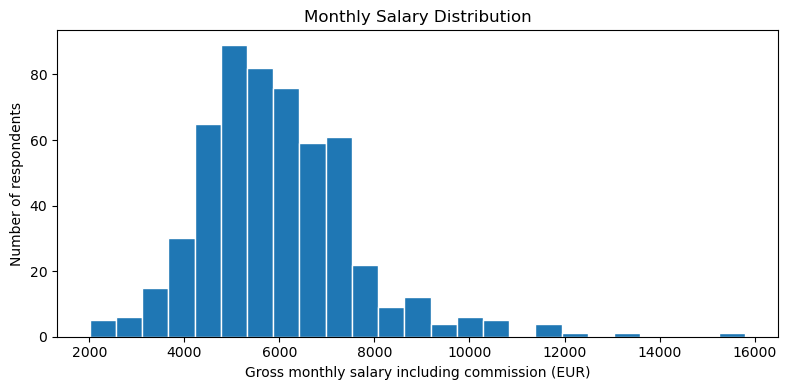

In [4]:
# Preserve the original sample for sensitivity analysis
data_with_extreme = data.copy()

# Exclude the single unverified extreme salary
data = data_with_extreme[
    data_with_extreme[target] != 92000
].copy()

print("Primary analysis sample:", len(data))
display(data[target].describe().round(2))

plt.figure(figsize=(8, 4))
plt.hist(data[target], bins=25, edgecolor="white")
plt.xlabel("Gross monthly salary including commission (EUR)")
plt.ylabel("Number of respondents")
plt.title("Monthly Salary Distribution")
plt.tight_layout()
plt.show()

## 4. Salary and Professional Experience

Salary distributions are examined by industry experience and seniority.
These descriptive comparisons help identify patterns and motivate the
prediction models. They do not establish causal effects.

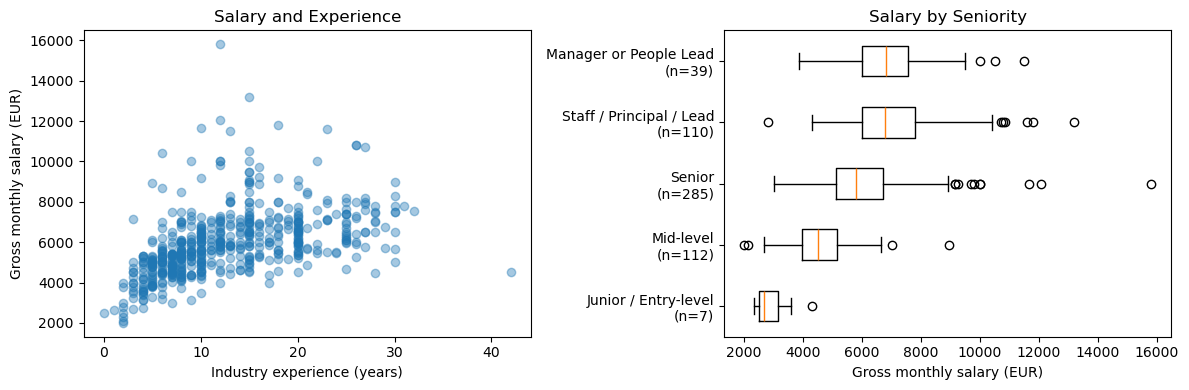

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Salary and years of experience
axes[0].scatter(
    data["Työkokemus alalta (vuosina)"],
    data[target],
    alpha=0.4,
)
axes[0].set_xlabel("Industry experience (years)")
axes[0].set_ylabel("Gross monthly salary (EUR)")
axes[0].set_title("Salary and Experience")

# Salary distribution by seniority
levels = [
    "Junior / Entry-level", "Mid-level", "Senior",
    "Staff / Principal / Lead", "Manager or People Lead",
]
values = [data.loc[data["Seniority"] == level, target] for level in levels]
labels = [f"{level}\n(n={len(v)})" for level, v in zip(levels, values)]

axes[1].boxplot(values, vert=False)
axes[1].set_yticks(range(1, len(levels) + 1))
axes[1].set_yticklabels(labels)
axes[1].set_xlabel("Gross monthly salary (EUR)")
axes[1].set_title("Salary by Seniority")

plt.tight_layout()
plt.show()

## 5. Training and Test Split

The data is randomly split into an 80% training set and a 20% test set.
The training set will be used for preprocessing, cross-validation, and
model selection. The test set will be reserved for final evaluation.

This evaluates prediction for held-out respondents from the same survey,
not future salary development or representativeness of the entire sector.

In [6]:
from sklearn.model_selection import train_test_split

X = data[features].copy()
y = data[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 442
Test observations: 111


## 6. Preprocessing

Industry experience and working-time ratio are standardized.
Categorical predictors are one-hot encoded, with categories appearing
fewer than 10 times in each training fold grouped together.

Preprocessing is included in the modeling pipelines so that transformations
are learned only from the training portion of each cross-validation fold.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = [
    "Työkokemus alalta (vuosina)",
    "Työaika",
]

categorical_features = [
    "Rooli (normalisoitu)",
    "Seniority",
    "Kaupunki",
    "Yrityksen koko",
]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(
        min_frequency=10,
        handle_unknown="infrequent_if_exist",
        drop="first",
        sparse_output=False,
    ), categorical_features),
])

## 7. Initial Model Comparison

A median-salary baseline is compared with Linear Regression, Ridge,
and Random Forest using the same five cross-validation folds.

Mean absolute error (MAE), measured in euros per month, is the primary
comparison metric. Lower values indicate better predictions.
This is an initial comparison before limited hyperparameter tuning.

In [8]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=1,
    ),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model),
    ])

    scores = -cross_val_score(
        pipeline, X_train, y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    )

    results.append({
        "Model": name,
        "CV MAE (EUR)": scores.mean(),
        "Fold SD (EUR)": scores.std(),
    })

comparison = pd.DataFrame(results).sort_values("CV MAE (EUR)")
display(comparison.round(2))

/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserW

,Model,CV MAE (EUR),Fold SD (EUR)
3,Random Forest,901.95,56.53
2,Ridge,903.46,43.66
1,Linear Regression,909.26,46.86
0,Median baseline,1235.89,146.21


## 8. Limited Hyperparameter Tuning

Ridge and Random Forest are tuned using the same five-fold
cross-validation scheme and MAE criterion. The search is deliberately
small because the dataset is limited.

Cross-validation scores guide model selection; the test set remains
unused until the final evaluation.

In [9]:
from sklearn.model_selection import GridSearchCV

searches = {}
tuning_results = []

settings = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1, 10, 100]},
    ),
    "Random Forest": (
        RandomForestRegressor(
            n_estimators=200, random_state=42, n_jobs=1
        ),
        {
            "model__max_depth": [3, 5, None],
            "model__min_samples_leaf": [3, 5, 10],
        },
    ),
}

for name, (model, parameters) in settings.items():
    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model),
    ])

    search = GridSearchCV(
        pipeline, parameters,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search

    tuning_results.append({
        "Model": name,
        "Best CV MAE (EUR)": -search.best_score_,
        "Parameters": search.best_params_,
    })

display(pd.DataFrame(tuning_results).round(2))

/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserW

,Model,Best CV MAE (EUR),Parameters
0,Ridge,902.21,{'model__alpha': 1}
1,Random Forest,894.78,"{'model__max_depth': 5, 'model__min_samples_le..."


## 9. Final Test Evaluation

Random Forest is selected based on the lowest cross-validation MAE.
Its advantage over Ridge is small.

The selected model is evaluated on the held-out test set and compared
with the training-set median baseline. Test results are not used for
further model selection or hyperparameter tuning.

MAE and RMSE are reported in euros per month. R² measures improvement
in squared error relative to predicting the test-set mean.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# GridSearchCV has already refitted this pipeline on all training data
final_model = searches["Random Forest"].best_estimator_

print("Selected model: Random Forest")
print("Parameters:", searches["Random Forest"].best_params_)

y_pred = final_model.predict(X_test)

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

test_results = []

for name, predictions in [
    ("Median baseline", baseline_pred),
    ("Selected Random Forest", y_pred),
]:
    test_results.append({
        "Model": name,
        "MAE (EUR)": mean_absolute_error(y_test, predictions),
        "RMSE (EUR)": mean_squared_error(y_test, predictions) ** 0.5,
        "R²": r2_score(y_test, predictions),
    })

display(pd.DataFrame(test_results).round(2))

Selected model: Random Forest
Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 3}


/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Model,MAE (EUR),RMSE (EUR),R²
0,Median baseline,1156.73,1614.01,-0.01
1,Selected Random Forest,845.85,1253.32,0.39


## 10. Prediction Errors

Test predictions are compared with reported salaries. The diagonal line
represents a perfect prediction.

Residuals are defined as reported salary minus predicted salary.
Positive residuals indicate underprediction; negative residuals indicate
overprediction. These plots are used for interpretation, not further tuning.

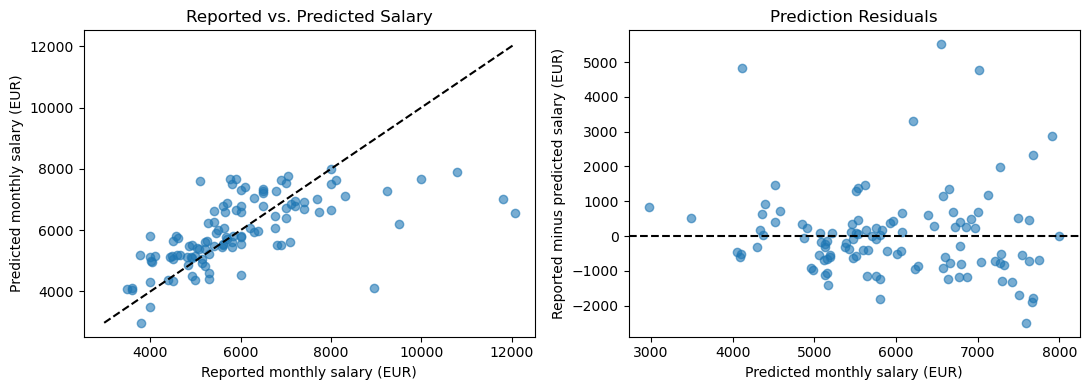

In [11]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Actual versus predicted salaries
axes[0].scatter(y_test, y_pred, alpha=0.6)
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max()),
]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_xlabel("Reported monthly salary (EUR)")
axes[0].set_ylabel("Predicted monthly salary (EUR)")
axes[0].set_title("Reported vs. Predicted Salary")

# Residuals versus predicted salaries
axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("Predicted monthly salary (EUR)")
axes[1].set_ylabel("Reported minus predicted salary (EUR)")
axes[1].set_title("Prediction Residuals")

plt.tight_layout()
plt.show()

### Interpretation of Test Errors

The model improves on the median baseline, but its predictions cover
a narrower range than the reported salaries. Several high salaries are
substantially underpredicted.

The test MAE is approximately EUR 846 per month, while the RMSE is
approximately EUR 1,253. The larger RMSE reflects the influence of
some substantial prediction errors.

These results suggest that the model captures broad salary patterns
but does not reliably identify unusually high compensation.
It should therefore not be treated as a precise salary recommendation
for an individual employee.

## 11. Sensitivity to the Extreme Salary Observation

The excluded EUR 92,000 salary observation is added to the training set.
The selected model settings and the original test set remain unchanged.

This analysis examines sensitivity to including the observation during
training. It does not evaluate prediction accuracy for extreme salaries
or guide further model tuning.

In [12]:
extreme = data_with_extreme[
    data_with_extreme[target] == 92000
]

X_train_extreme = pd.concat([X_train, extreme[features]])
y_train_extreme = pd.concat([y_train, extreme[target]])

sensitivity_model = clone(final_model)
sensitivity_model.fit(X_train_extreme, y_train_extreme)
sensitivity_pred = sensitivity_model.predict(X_test)

sensitivity_results = []

for name, predictions in [
    ("Primary analysis", y_pred),
    ("Extreme observation added to training", sensitivity_pred),
]:
    sensitivity_results.append({
        "Scenario": name,
        "Test MAE (EUR)": mean_absolute_error(y_test, predictions),
        "Test RMSE (EUR)": mean_squared_error(y_test, predictions) ** 0.5,
        "Test R²": r2_score(y_test, predictions),
    })

print("Extreme observations added:", len(extreme))
display(pd.DataFrame(sensitivity_results).round(2))

Extreme observations added: 1


/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Scenario,Test MAE (EUR),Test RMSE (EUR),Test R²
0,Primary analysis,845.85,1253.32,0.39
1,Extreme observation added to training,1187.48,2336.54,-1.12


### Sensitivity Analysis Interpretation

Adding the EUR 92,000 observation to the training set increased test MAE
from EUR 845.85 to EUR 1,187.48 and RMSE from EUR 1,253.32 to
EUR 2,336.54. Test R² decreased from 0.39 to -1.12.

The selected model is therefore sensitive to this extreme training
observation. This does not establish that the reported salary is incorrect.
Its exclusion from the primary analysis remains a documented data-quality
decision, and the results are conditional on that decision.

The original test set and model settings were unchanged.

## 12. Sensitivity to Remote-Only Location Responses

Respondents reporting only "remote work" are removed from the training
set. Model settings remain unchanged.

Both the primary model and the sensitivity model are evaluated on the
same test subset with explicitly reported Finnish locations. This isolates
the effect of retaining remote-only respondents during training.

The analysis does not establish the geographical location of remote
respondents and is not used for further model tuning.

In [13]:
# Exclude remote-only locations from training
domestic_train = X_train["Kaupunki"] != "Etätyö"
domestic_test = X_test["Kaupunki"] != "Etätyö"

location_model = clone(final_model)
location_model.fit(
    X_train.loc[domestic_train],
    y_train.loc[domestic_train],
)

# Compare both models on the same domestic test subset
X_domestic = X_test.loc[domestic_test]
y_domestic = y_test.loc[domestic_test]

location_results = []

for name, model in [
    ("Primary model", final_model),
    ("Remote-only training responses excluded", location_model),
]:
    predictions = model.predict(X_domestic)

    location_results.append({
        "Scenario": name,
        "MAE (EUR)": mean_absolute_error(y_domestic, predictions),
        "RMSE (EUR)": mean_squared_error(y_domestic, predictions) ** 0.5,
        "R²": r2_score(y_domestic, predictions),
    })

print("Remote-only training responses removed:", (~domestic_train).sum())
print("Shared domestic test observations:", len(y_domestic))
display(pd.DataFrame(location_results).round(2))

Remote-only training responses removed: 10
Shared domestic test observations: 109


/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/software/lib/python3.10/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Scenario,MAE (EUR),RMSE (EUR),R²
0,Primary model,855.30,1263.66,0.39
1,Remote-only training responses excluded,879.74,1297.51,0.35


### Interpretation of Location Sensitivity

Removing the 10 remote-only respondents from the training set increased
MAE from EUR 855.30 to EUR 879.74 on the same 109 test respondents
with explicitly reported Finnish locations. R² decreased from 0.39 to 0.35.

The change was modest in this comparison, and the main interpretation
remained similar. This does not verify the location of remote-only
respondents or establish robustness across other data splits.